## K-means and Hierarchical Clustering

We'll explore a few examples of clustering today.  The following sites may prove helpful:
- [https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html)
- [https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)
- [https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.dendrogram.html)

In [12]:
# As always, we start with our imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs # used just to make some example data
from sklearn.cluster import KMeans # <-- NEW!!! needed to build our k-means model
from sklearn.metrics import accuracy_score
from scipy.cluster.hierarchy import dendrogram, linkage # <-- NEW!!! needed to build our hierarchical model
from sklearn.datasets import load_iris

# for dbscan example
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN

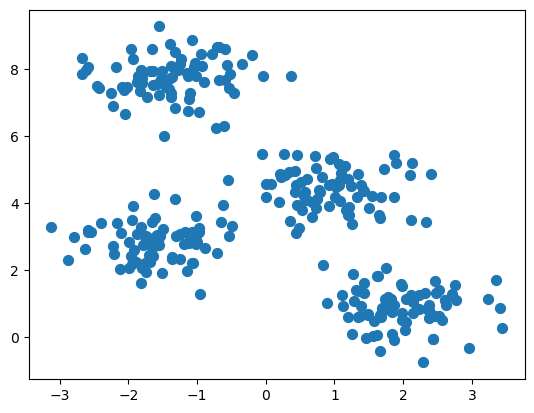

In [16]:
# just making some sample data for us to practice with
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50)

In [19]:
X

array([[ 8.36856841e-01,  2.13635938e+00],
       [-1.41365810e+00,  7.40962324e+00],
       [ 1.15521298e+00,  5.09961887e+00],
       [-1.01861632e+00,  7.81491465e+00],
       [ 1.27135141e+00,  1.89254207e+00],
       [ 3.43761754e+00,  2.61654166e-01],
       [-1.80822253e+00,  1.59701749e+00],
       [ 1.41372442e+00,  4.38117707e+00],
       [-2.04932168e-01,  8.43209665e+00],
       [-7.11099611e-01,  8.66043846e+00],
       [-1.71237268e+00,  2.77780226e+00],
       [-2.67000792e+00,  8.35389140e+00],
       [ 1.24258802e+00,  4.50399192e+00],
       [-2.22783649e+00,  6.89479938e+00],
       [ 1.45513831e+00, -2.91989981e-02],
       [ 4.53791789e-01,  3.95647753e+00],
       [ 1.06923853e+00,  4.53068484e+00],
       [ 2.56936589e+00,  5.07048304e-01],
       [-1.06690610e+00,  3.13165795e+00],
       [-1.07859101e+00,  2.20451529e+00],
       [ 2.71506328e+00,  1.29082190e+00],
       [ 1.77710994e+00,  1.18655254e+00],
       [ 7.34363910e-01,  5.03725437e+00],
       [-1.

We can see several clear clusters via visual inspection. Can k-means identify them?

Note: why am I am not using test and training data here? 

In [23]:
# Let's create and fit the model
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)


C:\Users\alm36\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


KMeans(n_clusters=4)

In [25]:
# to address possible error
import os
os.environ["OMP_NUM_THREADS"] = "2"

In [29]:
# now let's get the labels for each data point (predict)
y = kmeans.predict(X)


array([1, 0, 3, 0, 1, 1, 2, 3, 0, 0, 2, 0, 3, 0, 1, 3, 3, 1, 2, 2, 1, 1,
       3, 2, 2, 3, 1, 3, 2, 3, 0, 0, 3, 0, 0, 0, 0, 0, 2, 1, 3, 2, 3, 3,
       2, 2, 0, 2, 0, 1, 2, 1, 0, 1, 1, 2, 0, 2, 0, 1, 0, 3, 0, 2, 2, 2,
       0, 1, 0, 2, 3, 2, 0, 2, 2, 0, 2, 3, 1, 0, 1, 3, 1, 1, 0, 3, 1, 3,
       0, 0, 3, 1, 0, 2, 2, 3, 1, 1, 3, 2, 0, 1, 0, 1, 3, 1, 1, 3, 0, 3,
       2, 2, 1, 0, 1, 3, 0, 1, 1, 3, 2, 1, 2, 1, 1, 1, 1, 2, 1, 2, 0, 2,
       2, 1, 0, 2, 2, 0, 3, 0, 0, 2, 3, 2, 3, 2, 0, 3, 0, 0, 0, 3, 0, 3,
       1, 2, 0, 2, 1, 3, 0, 3, 3, 1, 3, 2, 2, 3, 1, 3, 3, 0, 1, 3, 2, 0,
       1, 1, 3, 2, 1, 3, 2, 2, 3, 3, 3, 3, 1, 0, 3, 2, 3, 3, 2, 2, 2, 3,
       2, 0, 3, 2, 1, 2, 3, 0, 2, 0, 3, 0, 3, 2, 3, 3, 0, 2, 2, 1, 1, 3,
       0, 1, 1, 2, 1, 2, 3, 0, 0, 3, 3, 0, 3, 1, 2, 3, 1, 2, 0, 2, 1, 3,
       1, 0, 0, 0, 0, 2, 2, 0, 3, 2, 1, 3, 2, 2, 2, 1, 1, 0, 3, 3, 2, 1,
       0, 2, 3, 0, 3, 1, 1, 2, 2, 3, 1, 1, 1, 3, 0, 0, 1, 1, 3, 1, 1, 1,
       0, 2, 0, 3, 1, 1, 0, 0, 0, 1, 1, 3, 0, 2])

In [31]:
# this provides the labels for each of the 300 samples
y

array([1, 0, 3, 0, 1, 1, 2, 3, 0, 0, 2, 0, 3, 0, 1, 3, 3, 1, 2, 2, 1, 1,
       3, 2, 2, 3, 1, 3, 2, 3, 0, 0, 3, 0, 0, 0, 0, 0, 2, 1, 3, 2, 3, 3,
       2, 2, 0, 2, 0, 1, 2, 1, 0, 1, 1, 2, 0, 2, 0, 1, 0, 3, 0, 2, 2, 2,
       0, 1, 0, 2, 3, 2, 0, 2, 2, 0, 2, 3, 1, 0, 1, 3, 1, 1, 0, 3, 1, 3,
       0, 0, 3, 1, 0, 2, 2, 3, 1, 1, 3, 2, 0, 1, 0, 1, 3, 1, 1, 3, 0, 3,
       2, 2, 1, 0, 1, 3, 0, 1, 1, 3, 2, 1, 2, 1, 1, 1, 1, 2, 1, 2, 0, 2,
       2, 1, 0, 2, 2, 0, 3, 0, 0, 2, 3, 2, 3, 2, 0, 3, 0, 0, 0, 3, 0, 3,
       1, 2, 0, 2, 1, 3, 0, 3, 3, 1, 3, 2, 2, 3, 1, 3, 3, 0, 1, 3, 2, 0,
       1, 1, 3, 2, 1, 3, 2, 2, 3, 3, 3, 3, 1, 0, 3, 2, 3, 3, 2, 2, 2, 3,
       2, 0, 3, 2, 1, 2, 3, 0, 2, 0, 3, 0, 3, 2, 3, 3, 0, 2, 2, 1, 1, 3,
       0, 1, 1, 2, 1, 2, 3, 0, 0, 3, 3, 0, 3, 1, 2, 3, 1, 2, 0, 2, 1, 3,
       1, 0, 0, 0, 0, 2, 2, 0, 3, 2, 1, 3, 2, 2, 2, 1, 1, 0, 3, 3, 2, 1,
       0, 2, 3, 0, 3, 1, 1, 2, 2, 3, 1, 1, 1, 3, 0, 0, 1, 1, 3, 1, 1, 1,
       0, 2, 0, 3, 1, 1, 0, 0, 0, 1, 1, 3, 0, 2])

Let's view what it predicted via plotting. 

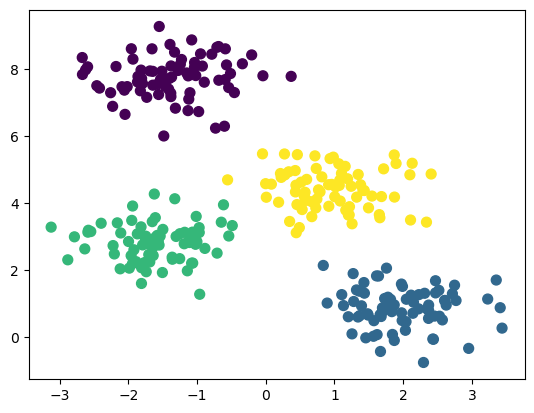

In [33]:
plt.scatter(X[:, 0], X[:, 1], c = y, s=50)

In [35]:
# we can access each like so
centers = kmeans.cluster_centers_
centers

array([[-1.37324398,  7.75368871],
       [ 1.98258281,  0.86771314],
       [-1.58438467,  2.83081263],
       [ 0.94973532,  4.41906906]])

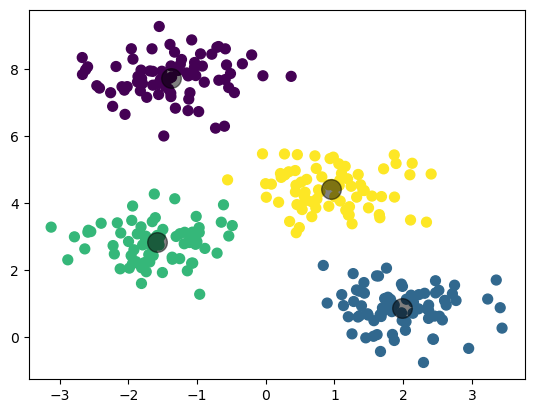

In [47]:
plt.scatter(X[:, 0], X[:, 1], c = y, s=50)
plt.scatter(centers[:,0], centers[:,1], c='black', alpha =.5, s=200)

In [49]:
# we can also access inertia
kmeans.inertia_

212.00599621083475

In [64]:
# let's compare to another value for K
kmeans = KMeans(n_clusters=11)
kmeans.fit(X)
y = kmeans.predict(X)

C:\Users\alm36\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Let's plot is again to visualize what we have. 

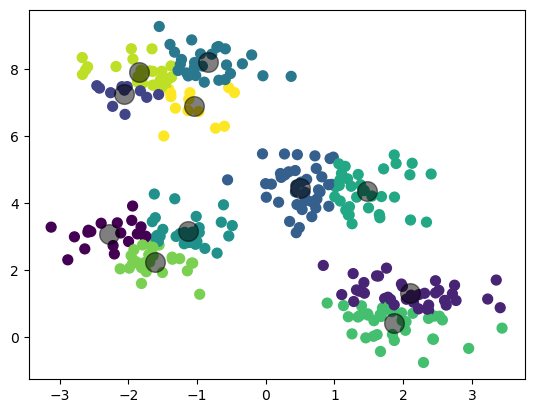

In [67]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50)

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c="black", s=200, alpha=0.5)

In [69]:
# inertia?
kmeans.inertia_

111.88195216725278

Which is actually better?

## Another Example

We'll load the digits dataset. This has handwritten digits from 0 to 9. It stores pixels values for each observation (image). Each image is actually an 8x8 pixel grayscale image, and represented as a 64 dimensional feature vector. Each number represents the pixel intensity. Our goal is to group similar handwritten digits together. 

See https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits for more about this dataset. And see https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html to see how this is imported.

In [71]:
from sklearn.datasets import load_digits
digits = load_digits(as_frame=True)
digits.data.shape

(1797, 64)

Here is a quick breakdown of how the feature values work in this dataset:
* The Scale: Each sample is an 8x8 image of a handwritten digit. The features represent individual pixels, and their values range strictly from 0 to 16.
* 0 (Minimum): Represents the background (completely white/empty space).
* 16 (Maximum): Represents the highest amount of ink or pressure (completely dark/black).
* 1 to 15: Represents intermediate shades of gray (anti-aliasing or lighter strokes).

In [73]:
digits.data

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0


<Figure size 640x480 with 0 Axes>

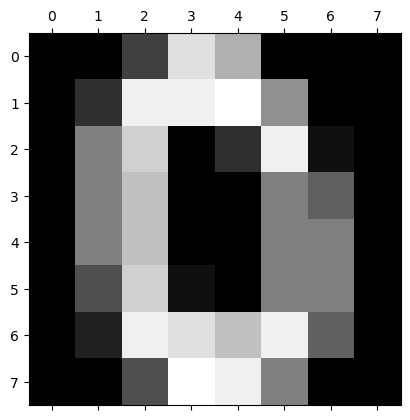

In [75]:
# Show plot in grayscale
plt.gray()
# Display a 2D array as a matrix in a new figure window.
plt.matshow(digits.images[79])

In [77]:
# we know this contains 10 digits... let's see if k-means can find them
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data) # note that this fits and predicts all in one step!!!! It returns array containing cluster values.
kmeans.cluster_centers_.shape

C:\Users\alm36\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


(10, 64)

Let's check out the centers visually, but we have to transform them a bit to make this more understandable.  

Note that if we just look at centers (as shown below), this isn't super informative. 

In [79]:
kmeans.cluster_centers_

array([[ 0.00000000e+00,  9.22651934e-01,  1.01104972e+01,
         1.44751381e+01,  7.86740331e+00,  1.06077348e+00,
        -6.66133815e-16,  0.00000000e+00,  2.20994475e-02,
         5.21546961e+00,  1.36464088e+01,  1.25856354e+01,
         1.16464088e+01,  3.37016575e+00,  2.20994475e-02,
         0.00000000e+00,  1.10497238e-02,  4.49723757e+00,
         8.08839779e+00,  6.06629834e+00,  1.21049724e+01,
         3.71823204e+00,  3.86740331e-02, -2.08166817e-17,
        -2.16840434e-19,  9.39226519e-01,  2.81767956e+00,
         7.00000000e+00,  1.25138122e+01,  2.76243094e+00,
         6.07734807e-02, -4.33680869e-19,  0.00000000e+00,
         4.41988950e-02,  1.59668508e+00,  9.86187845e+00,
         1.08342541e+01,  1.59668508e+00, -4.44089210e-16,
         0.00000000e+00, -1.73472348e-18,  2.43093923e-01,
         4.41988950e+00,  1.11325967e+01,  7.75138122e+00,
         2.60220994e+00,  9.39226519e-01,  1.10497238e-02,
         1.73472348e-18,  1.18232044e+00,  1.08950276e+0

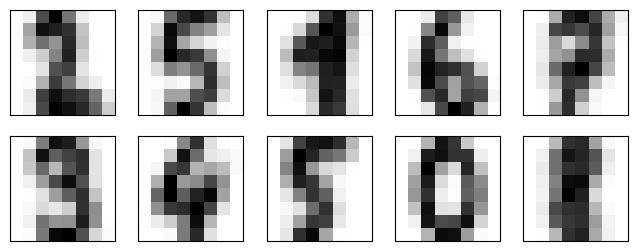

In [81]:
# get ready for plotting
fig, ax = plt.subplots(2, 5, figsize=(8, 3))

# Take the 10 K-Means cluster centers (each of length 64) and reshape them into 10 images of size 8×8 for visualization or analysis
# cluster centers is each center's coordinates. With 64 features, this means a cluster center has 64 values in a coordinate
# use 8 x 8 to represent the original image dimensions 

# For each subplot (axi) and its corresponding cluster center image (center), display that image on that subplot.
centers = kmeans.cluster_centers_.reshape(10, 8, 8)  
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[]) # removes tick marks for cleaner output
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary) # show image; place image in center of subplot & present as black and white colormap 

## Hierarchical Clustering 

Let's use our iris data set to see how it clusters the data without the label (target). Then we'll use the target to see if it is accurate.

In [14]:
# load iris and get a sample of the data
iris = load_iris(as_frame=True)
df = iris.frame
df = df.sample(frac=0.20, replace=True, random_state=1)

In [16]:
# let's see what we have
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
37,4.9,3.6,1.4,0.1,0
140,6.7,3.1,5.6,2.4,2
72,6.3,2.5,4.9,1.5,1
137,6.4,3.1,5.5,1.8,2
133,6.3,2.8,5.1,1.5,2
79,5.7,2.6,3.5,1.0,1
144,6.7,3.3,5.7,2.5,2
129,7.2,3.0,5.8,1.6,2
71,6.1,2.8,4.0,1.3,1
134,6.1,2.6,5.6,1.4,2


Let's build a pretty simple model using just the sepal length and width. 

In [20]:
# select just sepal length and width
X = df.iloc[:, 0:4] # leave out the class
y = df["target"]

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X_scaled
df = pd.DataFrame(X_scaled)
df

,0,1,2,3
0,0.115385,1.0000,0.083333,0.000000
1,0.807692,0.6875,0.958333,0.958333
2,0.653846,0.3125,0.812500,0.583333
3,0.692308,0.6875,0.937500,0.708333
4,0.653846,0.5000,0.854167,0.583333
5,0.423077,0.3750,0.520833,0.375000
6,0.807692,0.8125,0.979167,1.000000
7,1.000000,0.6250,1.000000,0.625000
8,0.576923,0.5000,0.625000,0.500000
9,0.576923,0.3750,0.958333,0.541667


In [26]:
# need labels in list to pass to plot below
clusterModel = linkage(df.iloc[:, 1:3], method = "single")

targets = y.tolist()

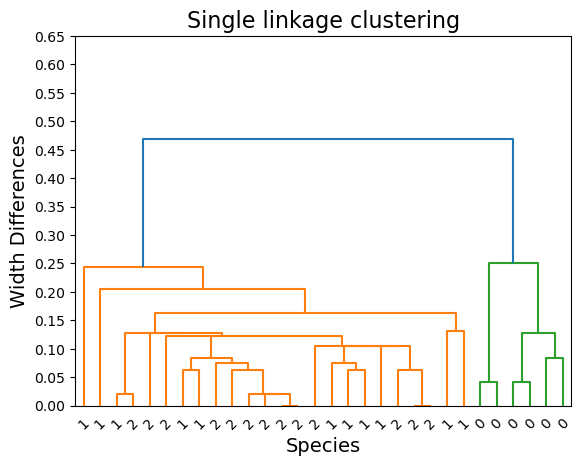

In [28]:
# Create the dendrogram
dendrogram(clusterModel, labels=targets)

# Plot the dendrogram
plt.ylabel('Width Differences', fontsize=14)
plt.yticks(np.arange(0, .7, step=.05))
plt.xlabel('Species', fontsize=14)
plt.title('Single linkage clustering', fontsize=16)
plt.show()

How did it do?

## DBSCAN Example

Let's begin by loading the data. We don't want to include customer score when we do clustering so, we'll select the features we need.

In [ ]:
df = pd.read_csv('Mall_Customers.csv')
X = df[['Age', 'AnnualIncome', 'SpendingScore']]
X

Distance-based methods should be scaled first. We'll use MinMax scaler this time.

In [ ]:
scaler = MinMaxScaler(feature_range=(0,10))
model = scaler.fit(X)
scaled_X = model.transform(X) # gives a ndarry
# put this back into a dataframe
X = pd.DataFrame(scaled_X, columns=X.columns)

Now we can create our DBSCAN model.
We'll specify max distance between samples for them to be consider in the same neighborhood (esp). This is the most important parameter to consider.
We'll also specify the min number of samples needed for a point to be considered a core point. 


Let's now add cluster labels to each observation in the ORIGINAL dataset.

In [ ]:
df.loc[:,'Cluster'] = DBSCANmodel.labels_ 
df['Cluster'] = df['Cluster'].astype(int)
df

Let's just see how many observations belong to each cluster.

In [ ]:
df.value_counts("Cluster").to_frame()

In [ ]:
# get outliers
outliers = df[df['Cluster']==-1]

# get non-outliers
non_outliers = df[df['Cluster']!=-1]

fig, (axes) = plt.subplots(1,2, figsize=(12,5))

# plot the clusters
sns.scatterplot(x='AnnualIncome', y='SpendingScore', data=non_outliers, hue='Cluster', ax=axes[0], s=50)
sns.scatterplot(x='Age', y='SpendingScore', data=non_outliers, hue='Cluster', ax=axes[1], s=50)

# add outliers to each plot
axes[0].scatter(outliers['AnnualIncome'], outliers['SpendingScore'], s=50, label='Outlier', c="y")
axes[1].scatter(outliers['Age'], outliers['SpendingScore'], s=50, label='Outlier', c="y")

# add legend
axes[0].legend()
axes[1].legend()

# see https://seaborn.pydata.org/generated/seaborn.move_legend.html
sns.move_legend(axes[0], "upper right", title="Cluster")
sns.move_legend(axes[1], "upper right", title="Cluster")

plt.show()

In [ ]:
What does this tell us? 